# Water Pump — Serial Hybrid Model (0.005)

**Objective:** Predict **Pump Brake Power** from operating conditions using a physics → ML → physics serial hybrid.

| Role | Variables |
|------|-----------|
| Inputs | Water Flow, Inlet Pressure, Outlet Pressure, Water Density |
| Output | Pump Brake Power (kW) |

**Serial chain**
1. **Physics** → Hydraulic Power \(P_{hyd} = Q \cdot \Delta P\)
2. **ML** → Efficiency \(\eta\)
3. **Physics** → Brake Power \(P_{brake} = P_{hyd} / \eta\)

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 20)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Load & clean data

In [2]:
# Load the raw data from Excel
df_raw = pd.read_excel("PumpData_0.005.xlsx")
print("Raw shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
df_raw.head()

# First row has units, so remove it and make everything numeric
df = df_raw.iloc[1:].copy()
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
# Drop any rows with missing values
df = df.dropna().reset_index(drop=True)

print("After numeric clean:", df.shape)
print("Nulls:\n", df.isnull().sum())
df.describe().T

# Find rows where brake power is zero or negative (not physical)
n_bad = (df["Pump Brake power"] <= 0).sum()
print(f"Rows with Brake Power <= 0: {n_bad}")

# Remove those rows from the data
df = df[df["Pump Brake power"] > 0].copy().reset_index(drop=True)
print("Clean shape:", df.shape)
df.head()

Raw shape: (313, 6)
Columns: ['Water Flow', 'Water inlet Pressure', 'Water outlet pressure', 'Water Density', 'Pump Brake power', 'Pump efficiency']
After numeric clean: (312, 6)
Nulls:
 Water Flow               0
Water inlet Pressure     0
Water outlet pressure    0
Water Density            0
Pump Brake power         0
Pump efficiency          0
dtype: int64
Rows with Brake Power <= 0: 2
Clean shape: (310, 6)


,Water Flow,Water inlet Pressure,Water outlet pressure,Water Density,Pump Brake power,Pump efficiency
0,500,6.013,25,999.9,0.6113,75
1,500,6.013,50,999.9,1.4160,75
2,500,6.013,75,999.9,2.2210,75
3,500,6.013,100,999.9,3.0260,75
4,500,6.013,125,999.9,3.8310,75


# Physics calculations for Stage 1 – Hydraulic Power:
# 
 Mass flow rate (kg/s):         ṁ = Water Flow / 3600
 Volumetric flow rate (m³/s):   Q = ṁ / ρ
 Pressure differential (Pa):    ΔP = (P_out - P_in) × 100,000
 Hydraulic Power (kW):          P_hyd = (Q × ΔP) / 1000
 
 Where:
- Water Flow in kg/h
 - ρ (rho) is Water Density in kg/m³
 - P_out, P_in in bar
- 100,000 converts bar to Pascals

In [3]:
def compute_hydraulic_power(water_flow, inlet_pressure, outlet_pressure, water_density):
    """Physics Stage 1: return hydraulic power in kW."""
    # Convert water flow from kg/h to kg/s
    mass_flow_kgs = water_flow / 3600.0
    # Convert mass flow to volumetric flow in m^3/s
    volumetric_flow_m3s = mass_flow_kgs / water_density
    # Compute pressure difference in Pascals
    delta_p_pa = (outlet_pressure - inlet_pressure) * 100_000.0
    # Calculate hydraulic power in kW
    hydraulic_power_kw = (volumetric_flow_m3s * delta_p_pa) / 1000.0
    return hydraulic_power_kw

# Calculate mass flow in kg/s
df["Mass Flow (kg/s)"] = df["Water Flow"] / 3600.0
# Calculate volumetric flow in m^3/s
df["Flow (m3/s)"] = df["Mass Flow (kg/s)"] / df["Water Density"]
# Calculate pressure difference in bar
df["Delta P (bar)"] = df["Water outlet pressure"] - df["Water inlet Pressure"]
# Convert pressure difference to Pascals
df["Delta P (Pa)"] = df["Delta P (bar)"] * 100_000.0
# Calculate hydraulic power in kW
df["Hydraulic Power (kW)"] = (df["Flow (m3/s)"] * df["Delta P (Pa)"]) / 1000.0

# Show preview of main physics columns
df[["Water Flow", "Delta P (bar)", "Hydraulic Power (kW)", "Pump Brake power"]].head(10)

,Water Flow,Delta P (bar),Hydraulic Power (kW),Pump Brake power
0,500,18.987,0.263735,0.6113
1,500,43.987,0.610992,1.4160
2,500,68.987,0.958249,2.2210
3,500,93.987,1.305506,3.0260
4,500,118.987,1.652762,3.8310
5,500,143.987,2.000019,4.6360
6,500,168.987,2.347276,5.4410
7,500,193.987,2.694533,6.2460
8,500,218.987,3.041790,7.0500
9,500,243.987,3.389047,7.8550


## 4. Observed efficiency & physics baseline

\[
\eta_{obs} = \frac{P_{hyd}}{P_{brake}}
\]

Physics-only baseline uses mean observed efficiency:
\(P_{brake}^{phys} = P_{hyd} / \bar{\eta}\).

In [4]:
# Calculate observed efficiency as hydraulic power divided by brake power
df["Observed Efficiency"] = df["Hydraulic Power (kW)"] / df["Pump Brake power"]

# Print summary statistics for observed efficiency
print("Observed Efficiency stats:")
print(df["Observed Efficiency"].describe())

# Compute average (mean) observed efficiency to use as baseline
baseline_efficiency = df["Observed Efficiency"].mean()

# Physics baseline: estimate brake power using baseline efficiency
df["Physics Brake Power"] = df["Hydraulic Power (kW)"] / baseline_efficiency

# Print the baseline efficiency value
print(f"\nBaseline (mean) efficiency: {baseline_efficiency:.6f}")

# Function to print and return common regression metrics
def report_metrics(name, y_true, y_pred, unit="kW"):
    mae = mean_absolute_error(y_true, y_pred)  # Mean Absolute Error
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))  # Root Mean Squared Error
    r2 = r2_score(y_true, y_pred)  # R squared (coefficient of determination)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100  # Mean Absolute Percentage Error
    print(f"{name}")
    print("-" * len(name))
    print(f"MAE  : {mae:.6f} {unit}")
    print(f"RMSE : {rmse:.6f} {unit}")
    print(f"R²   : {r2:.6f}")
    print(f"MAPE : {mape:.4f} %")
    print()
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape}

# Evaluate and report metrics for the physics baseline prediction
physics_metrics = report_metrics(
    "Physics Baseline — Brake Power",
    df["Pump Brake power"],       # True brake power
    df["Physics Brake Power"],    # Physics-estimated brake power
)

Observed Efficiency stats:
count    310.000000
mean       0.431425
std        0.000061
min        0.431255
25%        0.431392
50%        0.431428
75%        0.431459
max        0.431607
Name: Observed Efficiency, dtype: float64

Baseline (mean) efficiency: 0.431425
Physics Baseline — Brake Power
------------------------------
MAE  : 0.014179 kW
RMSE : 0.020820 kW
R²   : 1.000000
MAPE : 0.0107 %



## 5. Stage 2 — ML: Efficiency model

ML learns \(\eta\) from operating conditions + physics hydraulic power.

**Features:** Water Flow, Inlet P, Outlet P, Density, Hydraulic Power  
**Target:** Observed Efficiency  
**Model:** Linear Regression

In [5]:
# Define the feature columns to use for ML (inputs)
FEATURE_COLS = [
    "Water Flow",
    "Water inlet Pressure",
    "Water outlet pressure",
    "Water Density",
    "Hydraulic Power (kW)",
]
# Define the target variable (output)
TARGET_COL = "Observed Efficiency"

# Prepare features and target arrays
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

# Split data into training and test sets
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X, y, df, test_size=0.20, random_state=42
)

print("Train samples:", len(X_train))
print("Test  samples:", len(X_test))
print("Features:", FEATURE_COLS)

# Train and evaluate linear regression on split data
lr_eval = LinearRegression()
lr_eval.fit(X_train, y_train)  # Fit model to training data

y_train_pred = lr_eval.predict(X_train)
y_test_pred = lr_eval.predict(X_test)

print("Efficiency model (Linear Regression)")
print("====================================")
report_metrics("Train — Efficiency", y_train, y_train_pred, unit="")
report_metrics("Test  — Efficiency", y_test, y_test_pred, unit="")

# Train the final model on all the data for use in the digital twin
efficiency_model = LinearRegression()
efficiency_model.fit(X, y)

# Show the coefficients of the final model
print("Final efficiency model coefficients")
print("-----------------------------------")
for name, coef in zip(FEATURE_COLS, efficiency_model.coef_):
    print(f"{name:28s}: {coef:.6e}")
print(f"{'Intercept':28s}: {efficiency_model.intercept_:.6f}")

Train samples: 248
Test  samples: 62
Features: ['Water Flow', 'Water inlet Pressure', 'Water outlet pressure', 'Water Density', 'Hydraulic Power (kW)']
Efficiency model (Linear Regression)
Train — Efficiency
------------------
MAE  : 0.000046 
RMSE : 0.000060 
R²   : 0.006042
MAPE : 0.0107 %

Test  — Efficiency
------------------
MAE  : 0.000046 
RMSE : 0.000061 
R²   : -0.034342
MAPE : 0.0107 %

Final efficiency model coefficients
-----------------------------------
Water Flow                  : -1.920433e-10
Water inlet Pressure        : 8.271806e-25
Water outlet pressure       : -2.280031e-08
Water Density               : -8.078927e-39
Hydraulic Power (kW)        : -6.811585e-09
Intercept                   : 0.431431


## Feature importance — efficiency model

Raw coefficients are not comparable across features. Water Flow is hundreds of kg/h, density is ~1000 kg/m³, and the fitted coefficients are tiny.

Two views that *are* comparable:

1. **Standardized coefficient** — \(|\beta| \times \mathrm{std}(x)\): how much predicted efficiency moves for a 1-standard-deviation change in that feature (train-set scale, `lr_eval`).
2. **Permutation importance** on the hold-out test set: how much efficiency MAE rises when that feature is shuffled.

Both should sit near zero. Observed efficiency barely varies, so no operating-condition feature carries real signal.

Efficiency model — feature importance
                       std_effect   perm_mae  perm_std
Water outlet pressure   5.224e-06  3.725e-07 5.861e-07
Water Flow              5.748e-07  6.093e-08 1.001e-07
Water inlet Pressure    2.939e-39  0.000e+00 0.000e+00
Water Density           2.163e-52  0.000e+00 0.000e+00
Hydraulic Power (kW)    8.211e-07 -3.647e-09 9.371e-08


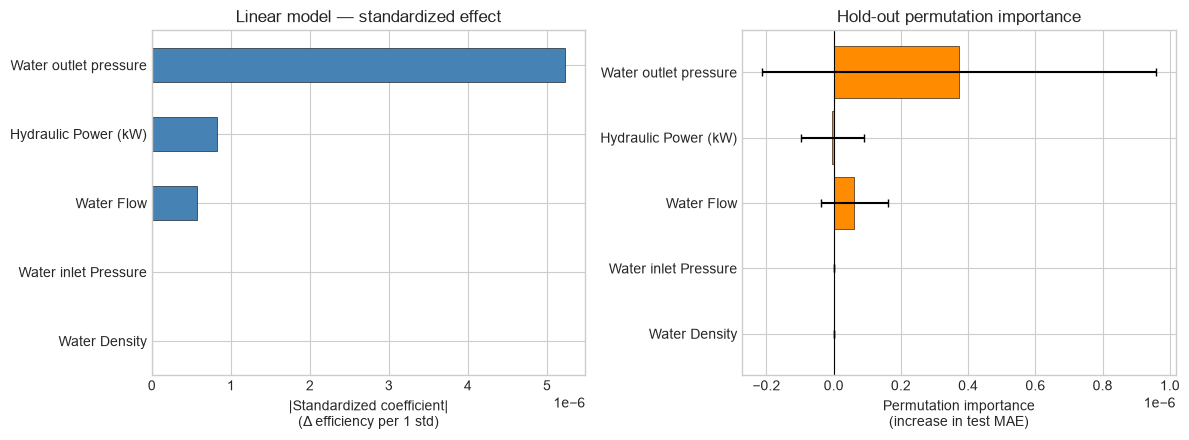

In [6]:
# Standardized effect: |coef| * train std = change in efficiency for a 1-std move
train_std = X_train.std(ddof=0)
std_effect = pd.Series(
    np.abs(lr_eval.coef_) * train_std.values,
    index=FEATURE_COLS,
    name="std_effect",
)

# Hold-out permutation importance: rise in test MAE when a feature is shuffled
perm = permutation_importance(
    lr_eval,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_absolute_error",
)
perm_mean = pd.Series(perm.importances_mean, index=FEATURE_COLS, name="perm_mae")
perm_std = pd.Series(perm.importances_std, index=FEATURE_COLS, name="perm_std")

importance = (
    pd.concat([std_effect, perm_mean, perm_std], axis=1)
    .sort_values("perm_mae", ascending=False)
)
print("Efficiency model — feature importance")
print(importance.to_string(float_format=lambda v: f"{v:.3e}"))

order = importance.sort_values("std_effect", ascending=True).index

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
std_effect.loc[order].plot.barh(ax=ax, color="steelblue", edgecolor="k", linewidth=0.4)
ax.set_xlabel("|Standardized coefficient|\n(Δ efficiency per 1 std)")
ax.set_title("Linear model — standardized effect")

ax = axes[1]
ax.barh(
    order,
    perm_mean.loc[order].values,
    xerr=perm_std.loc[order].values,
    color="darkorange",
    edgecolor="k",
    linewidth=0.4,
    capsize=3,
)
ax.axvline(0, color="k", linewidth=0.8)
ax.set_xlabel("Permutation importance\n(increase in test MAE)")
ax.set_title("Hold-out permutation importance")

plt.tight_layout()
plt.show()

## 6. Stage 3 — Serial Hybrid prediction

\[
P_{brake}^{hybrid} = \frac{P_{hyd}}{\eta_{ML}}
\]

In [7]:
def serial_hybrid_predict(water_flow, inlet_pressure, outlet_pressure, water_density,
                          model=efficiency_model):
    """
    Serial Hybrid Water Pump Model

    Stage 1 (Physics): Hydraulic Power
    Stage 2 (ML)     : Efficiency
    Stage 3 (Physics): Brake Power = Phyd / eta
    """
    # Check inputs
    if water_flow <= 0:
        raise ValueError("Water Flow must be > 0.")
    if water_density <= 0:
        raise ValueError("Water Density must be > 0.")
    if outlet_pressure <= inlet_pressure:
        raise ValueError("Outlet pressure must be greater than inlet pressure.")

    # 1. Compute hydraulic power using physics
    hydraulic_power_kw = compute_hydraulic_power(
        water_flow, inlet_pressure, outlet_pressure, water_density
    )

    # 2. Predict efficiency using ML model
    model_input = pd.DataFrame({
        "Water Flow": [water_flow],
        "Water inlet Pressure": [inlet_pressure],
        "Water outlet pressure": [outlet_pressure],
        "Water Density": [water_density],
        "Hydraulic Power (kW)": [hydraulic_power_kw],
    })
    eta_pred = float(model.predict(model_input)[0])

    # Check that predicted efficiency is in a valid range
    if eta_pred <= 0 or eta_pred > 1:
        raise ValueError(f"Predicted efficiency is physically invalid: {eta_pred}")

    # 3. Compute brake power using predicted efficiency
    brake_power_kw = hydraulic_power_kw / eta_pred

    return {
        "Hydraulic Power (kW)": hydraulic_power_kw,
        "Predicted Efficiency": eta_pred,
        "Predicted Brake Power (kW)": brake_power_kw,
    }


# Use the hybrid model to predict over the full dataset
hybrid_preds = [
    serial_hybrid_predict(
        row["Water Flow"],
        row["Water inlet Pressure"],
        row["Water outlet pressure"],
        row["Water Density"],
    )
    for _, row in df.iterrows()
]

# Extract predictions from results and store in dataframe columns
df["ML Efficiency"] = [p["Predicted Efficiency"] for p in hybrid_preds]
df["Hybrid Brake Power"] = [p["Predicted Brake Power (kW)"] for p in hybrid_preds]

# Print metrics comparing baseline physics and serial hybrid
print("Serial Hybrid vs Physics Baseline (full clean set)")
print("=================================================")
report_metrics("Physics Brake Power", df["Pump Brake power"], df["Physics Brake Power"])
report_metrics("Hybrid  Brake Power", df["Pump Brake power"], df["Hybrid Brake Power"])

Serial Hybrid vs Physics Baseline (full clean set)
Physics Brake Power
-------------------
MAE  : 0.014179 kW
RMSE : 0.020820 kW
R²   : 1.000000
MAPE : 0.0107 %

Hybrid  Brake Power
-------------------
MAE  : 0.014134 kW
RMSE : 0.020855 kW
R²   : 1.000000
MAPE : 0.0107 %



{'MAE': 0.014133505415920511,
 'RMSE': np.float64(0.020854730780098918),
 'R2': 0.9999999656546251,
 'MAPE': np.float64(0.010655053971283647)}

In [8]:
# Evaluate brake power predictions on hold-out test set

test_hybrid = []
for _, row in df_test.iterrows():
    phyd = row["Hydraulic Power (kW)"]  # Get hydraulic power from current row
    # Prepare a single-row DataFrame for ML efficiency prediction
    x_row = pd.DataFrame([{
        "Water Flow": row["Water Flow"],
        "Water inlet Pressure": row["Water inlet Pressure"],
        "Water outlet pressure": row["Water outlet pressure"],
        "Water Density": row["Water Density"],
        "Hydraulic Power (kW)": phyd,
    }])
    eta = float(lr_eval.predict(x_row)[0])  # Predict efficiency
    test_hybrid.append(phyd / eta)  # Calculate hybrid brake power

df_test = df_test.copy()
df_test["Hybrid Brake Power"] = test_hybrid  # Store hybrid brake power predictions
df_test["Physics Brake Power"] = df_test["Hydraulic Power (kW)"] / baseline_efficiency  # Compute baseline brake power

print("Hold-out TEST set — Brake Power")
print("================================")
# Print metrics for both physics-based and hybrid brake power predictions
report_metrics("Physics", df_test["Pump Brake power"], df_test["Physics Brake Power"])
report_metrics("Hybrid ", df_test["Pump Brake power"], df_test["Hybrid Brake Power"])

Hold-out TEST set — Brake Power
Physics
-------
MAE  : 0.012645 kW
RMSE : 0.019359 kW
R²   : 1.000000
MAPE : 0.0108 %

Hybrid 
-------
MAE  : 0.012602 kW
RMSE : 0.019504 kW
R²   : 1.000000
MAPE : 0.0107 %



{'MAE': 0.012602033818347723,
 'RMSE': np.float64(0.019504173863135115),
 'R2': 0.9999999666318395,
 'MAPE': np.float64(0.010699606776250469)}

## 7. Plots

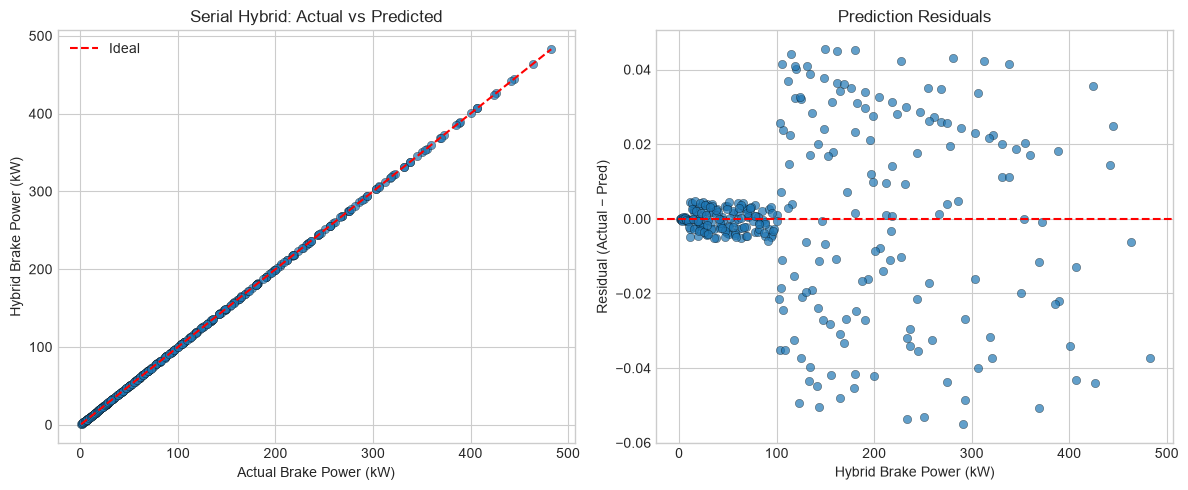

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # Create a figure with 2 side-by-side plots

# Left plot: Actual vs Predicted brake power
ax = axes[0]
ax.scatter(
    df["Pump Brake power"],           # X: actual brake power
    df["Hybrid Brake Power"],         # Y: predicted (hybrid) brake power
    alpha=0.7, edgecolor="k", linewidth=0.3
)
lims = [
    min(df["Pump Brake power"].min(), df["Hybrid Brake Power"].min()),  # Smallest value for diagonal line
    max(df["Pump Brake power"].max(), df["Hybrid Brake Power"].max()),  # Largest value for diagonal line
]
ax.plot(lims, lims, "r--", label="Ideal")  # Plot y=x line (perfect prediction)
ax.set_xlabel("Actual Brake Power (kW)")
ax.set_ylabel("Hybrid Brake Power (kW)")
ax.set_title("Serial Hybrid: Actual vs Predicted")
ax.legend()

# Right plot: Residuals of prediction (difference between actual and predicted)
ax = axes[1]
residual = df["Pump Brake power"] - df["Hybrid Brake Power"]  # Calculate residuals
ax.scatter(
    df["Hybrid Brake Power"],   # X: predicted brake power
    residual,                   # Y: difference (actual - predicted)
    alpha=0.7, edgecolor="k", linewidth=0.3
)
ax.axhline(0, color="r", linestyle="--")     # Draw horizontal line at 0
ax.set_xlabel("Hybrid Brake Power (kW)")
ax.set_ylabel("Residual (Actual − Pred)")
ax.set_title("Prediction Residuals")

plt.tight_layout()  # Adjust layout to fit everything
plt.show()          # Display plots

## 8. Demo prediction & save model

In [10]:
# Take the first row from the dataframe as a sample point
sample = df.iloc[0]

# Run the serial hybrid prediction on this sample point
result = serial_hybrid_predict(
    water_flow=sample["Water Flow"],
    inlet_pressure=sample["Water inlet Pressure"],
    outlet_pressure=sample["Water outlet pressure"],
    water_density=sample["Water Density"],
)

# Print out the input values of the sample
print("DEMO OPERATING POINT")
print("--------------------")
print(f"Water Flow           : {sample['Water Flow']:.1f} kg/h")
print(f"Inlet Pressure       : {sample['Water inlet Pressure']:.3f} bar")
print(f"Outlet Pressure      : {sample['Water outlet pressure']:.3f} bar")
print(f"Water Density        : {sample['Water Density']:.1f} kg/m3")
print()

# Print prediction results for this sample
print("SERIAL HYBRID OUTPUT")
print("--------------------")
print(f"Hydraulic Power      : {result['Hydraulic Power (kW)']:.6f} kW")
print(f"Predicted Efficiency : {result['Predicted Efficiency'] * 100:.2f} %")
print(f"Predicted Brake Power: {result['Predicted Brake Power (kW)']:.6f} kW")
print(f"Actual Brake Power   : {sample['Pump Brake power']:.6f} kW")

# Demo: predict for a high-load operating point
demo = serial_hybrid_predict(
    water_flow=20000,
    inlet_pressure=6.013,
    outlet_pressure=250,
    water_density=999.9,
)
print("High-load demo:", demo)

# Save the model and parameters to a file
model_path = "water_pump_serial_hybrid_efficiency_0.005.pkl"
joblib.dump(
    {
        "efficiency_model": efficiency_model,
        "feature_cols": FEATURE_COLS,
        "baseline_efficiency": baseline_efficiency,
        "units": {
            "Water Flow": "kg/h",
            "Pressure": "bar",
            "Water Density": "kg/m3",
            "Brake Power": "kW",
        },
    },
    model_path,
)
print(f"Saved → {model_path}")

DEMO OPERATING POINT
--------------------
Water Flow           : 500.0 kg/h
Inlet Pressure       : 6.013 bar
Outlet Pressure      : 25.000 bar
Water Density        : 999.9 kg/m3

SERIAL HYBRID OUTPUT
--------------------
Hydraulic Power      : 0.263735 kW
Predicted Efficiency : 43.14 %
Predicted Brake Power: 0.611303 kW
Actual Brake Power   : 0.611300 kW
High-load demo: {'Hydraulic Power (kW)': 135.56188952228555, 'Predicted Efficiency': 0.43142082856903263, 'Predicted Brake Power (kW)': 314.22193956635545}
Saved → water_pump_serial_hybrid_efficiency_0.005.pkl
